In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../Base_de_datos.csv', sep=';')

In [3]:
df.head()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,...,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,7/01/2025 14:40,1852560,12,32,Empleado,3500000,1000000,128650,"95,227787",...,0.0,0.0,NaN,NaN,0,0,0,916148.0,Creciente,1
1,4,9/01/2025 11:18,3181080,6,34,Empleado,5000000,2000000,441817,"95,227787",...,0.0,0.0,NaN,NaN,0,0,0,4473774.0,Creciente,1
2,9,26/12/2024 18:52,670200,5,34,Independiente,5000000,2000000,108632,"95,227787",...,0.0,274561.0,274561.0,NaN,2,0,1,NaN,NaN,1
3,9,4/12/2024 14:20,506807,2,25,Independiente,3000000,900000,199684,"95,227787",...,0.0,27564.0,27564.0,NaN,1,0,6,NaN,NaN,1
4,4,30/04/2025 18:41,999780,10,26,Empleado,2000000,600000,92509,"95,227787",...,0.0,0.0,NaN,NaN,0,0,0,61000.0,Creciente,1


In [4]:
df.shape

(10763, 23)

La base de datos tiene 10.763 registros y 23 variables. Con esta cantidad de información se puede empezar a revisar cómo están distribuidos los datos, qué variables pueden ser útiles y si existen problemas que debamos corregir antes de entrenar un modelo.


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tipo_credito                   10763 non-null  int64  
 1   fecha_prestamo                 10763 non-null  str    
 2   capital_prestado               10763 non-null  int64  
 3   plazo_meses                    10763 non-null  int64  
 4   edad_cliente                   10763 non-null  int64  
 5   tipo_laboral                   10763 non-null  str    
 6   salario_cliente                10763 non-null  int64  
 7   total_otros_prestamos          10763 non-null  int64  
 8   cuota_pactada                  10763 non-null  int64  
 9   puntaje                        10763 non-null  str    
 10  puntaje_datacredito            10757 non-null  float64
 11  cant_creditosvigentes          10763 non-null  int64  
 12  huella_consulta                10763 non-null  int64  
 1

En esta primera revisión se observa cómo está guardada cada variable y cuántos datos válidos tiene que nos permite identificar si alguna columna está en un tipo incorrecto, si hay valores faltantes o si necesitamos hacer conversiones antes de seguir con el análisis.

In [6]:
df.dtypes

tipo_credito                       int64
fecha_prestamo                       str
capital_prestado                   int64
plazo_meses                        int64
edad_cliente                       int64
tipo_laboral                         str
salario_cliente                    int64
total_otros_prestamos              int64
cuota_pactada                      int64
puntaje                              str
puntaje_datacredito              float64
cant_creditosvigentes              int64
huella_consulta                    int64
saldo_mora                       float64
saldo_total                      float64
saldo_principal                  float64
saldo_mora_codeudor              float64
creditos_sectorFinanciero          int64
creditos_sectorCooperativo         int64
creditos_sectorReal                int64
promedio_ingresos_datacredito    float64
tendencia_ingresos                   str
Pago_atiempo                       int64
dtype: object

Al revisar los tipos de datos se observa que la mayoría de las variables numéricas fueron reconocidas correctamente, pero hay algunas columnas que requieren revisión. `fecha_prestamo` aparece como texto y debería convertirse a fecha. `puntaje` también aparece como texto, por lo que es necesario revisar sus valores antes de decidir si debe convertirse a numérico y variables como `tipo_credito`, aunque aparecen como enteras, podrían representar categorías codificadas y no una cantidad numérica.

In [7]:
df.isnull().sum()

tipo_credito                        0
fecha_prestamo                      0
capital_prestado                    0
plazo_meses                         0
edad_cliente                        0
tipo_laboral                        0
salario_cliente                     0
total_otros_prestamos               0
cuota_pactada                       0
puntaje                             0
puntaje_datacredito                 6
cant_creditosvigentes               0
huella_consulta                     0
saldo_mora                        156
saldo_total                       156
saldo_principal                   405
saldo_mora_codeudor               590
creditos_sectorFinanciero           0
creditos_sectorCooperativo          0
creditos_sectorReal                 0
promedio_ingresos_datacredito    2930
tendencia_ingresos               2932
Pago_atiempo                        0
dtype: int64

Al revisar los valores nulos se observa que la mayoría de las variables están completas, auqnue algunas columnas sí presentan datos faltantes, especialmente `promedio_ingresos_datacredito` con 2.930 y `tendencia_ingresos` con 2.932. También aparecen nulos en algunas variables relacionadas con saldos y en `puntaje_datacredito`. Más adelante se debe revisar qué significan estos faltantes antes de decidir cómo tratarlos.

In [8]:
df.nunique()

tipo_credito                         6
fecha_prestamo                   10444
capital_prestado                  7306
plazo_meses                         18
edad_cliente                        54
tipo_laboral                         2
salario_cliente                   1385
total_otros_prestamos             1538
cuota_pactada                     9836
puntaje                            248
puntaje_datacredito                315
cant_creditosvigentes               39
huella_consulta                     28
saldo_mora                          55
saldo_total                       8858
saldo_principal                   8647
saldo_mora_codeudor                  4
creditos_sectorFinanciero           33
creditos_sectorCooperativo          11
creditos_sectorReal                 24
promedio_ingresos_datacredito     5309
tendencia_ingresos                  46
Pago_atiempo                         2
dtype: int64

Al revisar la cantidad de valores únicos se observa que algunas variables tienen muy pocas categorías. Por ejemplo, `tipo_laboral` y `Pago_atiempo` tienen 2 valores distintos, mientras que `tipo_credito` tiene 6. También se ve que `fecha_prestamo` presenta una gran cantidad de valores diferentes y que `tendencia_ingresos` tiene 46 valores únicos, por lo que conviene revisar más adelante cuáles son esos valores.

In [10]:
df['tipo_credito'].value_counts(dropna=False)

tipo_credito
4     7747
9     2876
10     116
6       21
7        2
68       1
Name: count, dtype: int64

En `tipo_credito` se observan 6 valores diferentes. La mayoría de los registros se concentran en los códigos 4 y 9, mientras que otros aparecen con mucha menor frecuencia. También llama la atención el valor 68, ya que solo aparece una vez, por lo que conviene revisar más adelante si corresponde a una categoría válida o a un dato inconsistente.

In [11]:
df['tipo_laboral'].value_counts(dropna=False)

tipo_laboral
Empleado         6754
Independiente    4009
Name: count, dtype: int64

La variable `tipo_laboral` tiene dos categorías: Empleado e Independiente. La categoría Empleado es la más frecuente, con 6.754 registros, mientras que Independiente aparece en 4.009 registros.

In [12]:
df['puntaje'].value_counts(dropna=False).head(20)

puntaje
95,227787     9407
89,979287       99
89,2295         82
91,99794        73
47,613894       59
84,730786       59
91,728786       56
92,228643       51
90,562453       46
91,410695       45
88,229786       44
86,830187       34
81,231786       29
91,028987       25
85,897119       21
58,597591       17
-5,102625       16
-18,471029      16
92,428587       14
88,768094       13
Name: count, dtype: int64

En `puntaje` los valores parecen corresponder a números decimales, pero la columna está almacenada como texto, puede deberse al uso de la coma como separador decimal. También se observan algunos valores negativos, por lo que antes de convertir la variable a numérica será necesario revisar si estos valores son válidos dentro del significado de la variable.

In [13]:
df['tendencia_ingresos'].value_counts(dropna=False).head(30)

tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
168750            1
-28589            1
-566272           1
24702             1
31837             1
122727            1
417087            1
9090              1
173031            1
-70715            1
-435177           1
-702927           1
-4105             1
54683             1
22832             1
209090            1
5697              1
-288              1
-164315           1
2029000           1
Name: count, dtype: int64

En `tendencia_ingresos` se observan las categorías Creciente, Decreciente y Estable, que son coherentes con el significado de la variable, pero también aparecen valores numéricos positivos y negativos dentro de la misma columna. Esto muestra una inconsistencia en la forma en que está registrada la información y será necesario revisar y limpiar estos valores antes de utilizar la variable.

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tipo_credito,10763.0,5.411131e+00,2.338279e+00,4.0,4.0,4.0,9.00,6.800000e+01
capital_prestado,10763.0,2.434315e+06,1.909643e+06,360000.0,1224831.0,1921920.0,3084840.00,4.144415e+07
plazo_meses,10763.0,1.057558e+01,6.632082e+00,2.0,6.0,10.0,12.00,9.000000e+01
edad_cliente,10763.0,4.394862e+01,1.506088e+01,19.0,33.0,42.0,53.00,1.230000e+02
salario_cliente,10763.0,1.721643e+07,3.554767e+08,0.0,2000000.0,3000000.0,4875808.00,2.200000e+10
total_otros_prestamos,10763.0,6.238870e+06,1.184183e+08,0.0,500000.0,1000000.0,2000000.00,6.787675e+09
cuota_pactada,10763.0,2.436174e+05,2.104937e+05,23944.0,121041.5,182863.0,287833.50,3.816752e+06
puntaje_datacredito,10757.0,7.807908e+02,1.048780e+02,-7.0,757.0,791.0,825.00,9.990000e+02
cant_creditosvigentes,10763.0,5.726749e+00,3.977162e+00,0.0,3.0,5.0,8.00,6.200000e+01
huella_consulta,10763.0,4.228561e+00,3.064683e+00,0.0,2.0,4.0,6.00,2.900000e+01


Al revisar las estadísticas descriptivas se observan varios valores que llaman la atención. `edad_cliente` tiene un mínimo de 19 años y un máximo de 123, por lo que ese valor máximo debería revisarse. En `salario_cliente` también se observa una diferencia muy grande entre los valores habituales y el máximo, que llega a 22.000.000.000. Algo similar ocurre con `total_otros_prestamos`, que el valor máximo es mucho mayor que los valores centrales.

También se observa que `puntaje_datacredito` presenta un valor mínimo de -7, mientras que la mayoría de los datos se encuentran en valores mucho más altos y algunas variables de saldos y cantidades de créditos presentan máximos bastante alejados de sus valores centrales, por lo que será necesario analizarlos con más detalle mediante gráficos como boxplots antes de tomar decisiones.

In [15]:
df['fecha_prestamo'] = pd.to_datetime(df['fecha_prestamo'], errors='coerce', dayfirst=True)

In [16]:
df['puntaje'] = (
    df['puntaje']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [17]:
df[['fecha_prestamo', 'puntaje']].dtypes

fecha_prestamo    datetime64[us]
puntaje                  float64
dtype: object

Se corrigieron los tipos de datos de `fecha_prestamo` y `puntaje`. La fecha pasó de estar almacenada como texto a un tipo de fecha, y `puntaje` pasó de texto a número decimal después de reemplazar la coma por punto y con esto estas variables ya pueden analizarse correctamente en las siguientes etapas del EDA.

In [18]:
df['tendencia_ingresos'].unique()

<StringArray>
[  'Creciente',           nan,     'Estable', 'Decreciente',        '8315',
           '0',      '158042',        '3978',        '9147',      '168750',
      '-28589',     '1000000',     '-566272',       '24702',       '31837',
      '122727',      '417087',        '9090',      '173031',      '-70715',
     '-435177',     '-702927',       '-4105',       '54683',       '22832',
      '209090',        '5697',        '-288',     '-164315',     '2029000',
       '17181',       '15245',       '82657',       '52862',     '1817052',
       '75761',      '146918',     '1123000',       '15090',     '4250635',
       '22363',     '-101368',       '86286',       '65988',       '77975',
     '-224714',       '10808']
Length: 47, dtype: str

In [19]:
df['tendencia_ingresos'].value_counts(dropna=False)

tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
168750            1
-28589            1
-566272           1
24702             1
31837             1
122727            1
417087            1
9090              1
173031            1
-70715            1
-435177           1
-702927           1
-4105             1
54683             1
22832             1
209090            1
5697              1
-288              1
-164315           1
2029000           1
17181             1
15245             1
82657             1
52862             1
1817052           1
75761             1
146918            1
1123000           1
15090             1
4250635           1
22363             1
-101368           1
86286             1
65988             1
77975             1
-224714           1
10808             1
Name: count, dtype: int64

En `tendencia_ingresos` se ven principalmente las categorías `Creciente`, `Decreciente` y `Estable`, pero también aparecen varios números que no corresponden con esas categorías, indica que hay datos mezclados dentro de la misma columna y que más adelante habrá que revisar cómo corregirlos.

In [20]:
categorias_validas = ['Creciente', 'Decreciente', 'Estable']

(~df['tendencia_ingresos'].isin(categorias_validas) &
 df['tendencia_ingresos'].notna()).sum()

np.int64(58)

Se encontraron 58 registros en `tendencia_ingresos` con valores que no corresponden a las categorías esperadas (`Creciente`, `Decreciente` y `Estable`). Esto confirma que hay datos inconsistentes en esta columna.

In [22]:
df.loc[
    ~df['tendencia_ingresos'].isin(categorias_validas) &
    df['tendencia_ingresos'].notna(),
    'tendencia_ingresos'
] = np.nan

In [23]:
df['tendencia_ingresos'].value_counts(dropna=False)

tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64

Se reemplazaron por valores nulos los 58 registros de `tendencia_ingresos` que no correspondían a las categorías `Creciente`, `Decreciente` o `Estable`. Después de esta limpieza, la columna queda únicamente con esas tres categorías y valores nulos, dejando la información más consistente para continuar con el análisis.

In [24]:
df.duplicated().sum()

np.int64(0)

No se encontraron filas duplicadas en la base de datos, ya que el resultado fue 0 y por esta razón, en este punto no es necesario eliminar registros por duplicidad.

### Caracterización de las variables

| Variable | Caracterización | Observación |
|---|---|---|
| `tipo_credito` | Categórica nominal politómica | Tiene 6 códigos diferentes que representan tipos de crédito. |
| `fecha_prestamo` | Fecha / temporal | Representa la fecha en la que se realizó el préstamo. |
| `capital_prestado` | Numérica | Representa el valor del dinero prestado. |
| `plazo_meses` | Numérica discreta | Indica la cantidad de meses establecidos para pagar el crédito. |
| `edad_cliente` | Numérica discreta | Representa la edad del cliente en años. |
| `tipo_laboral` | Categórica nominal dicotómica | Tiene dos categorías: Empleado e Independiente. |
| `salario_cliente` | Numérica | Representa el salario registrado del cliente. |
| `total_otros_prestamos` | Numérica | Representa el valor asociado a otros préstamos del cliente. |
| `cuota_pactada` | Numérica | Corresponde al valor de la cuota establecida para el crédito. |
| `puntaje` | Numérica | Es un valor decimal que inicialmente estaba almacenado como texto. |
| `puntaje_datacredito` | Numérica | Representa el puntaje registrado en Datacrédito. |
| `cant_creditosvigentes` | Numérica discreta | Indica la cantidad de créditos vigentes del cliente. |
| `huella_consulta` | Numérica discreta | Representa una cantidad de consultas registradas. |
| `saldo_mora` | Numérica | Representa el saldo que se encuentra en mora. |
| `saldo_total` | Numérica | Representa el saldo total registrado. |
| `saldo_principal` | Numérica | Representa el saldo principal. |
| `saldo_mora_codeudor` | Numérica | Representa el saldo en mora asociado al codeudor. |
| `creditos_sectorFinanciero` | Numérica discreta | Representa la cantidad de créditos en el sector financiero. |
| `creditos_sectorCooperativo` | Numérica discreta | Representa la cantidad de créditos en el sector cooperativo. |
| `creditos_sectorReal` | Numérica discreta | Representa la cantidad de créditos en el sector real. |
| `promedio_ingresos_datacredito` | Numérica | Representa el promedio de ingresos registrado en Datacrédito. |
| `tendencia_ingresos` | Categórica ordinal politómica | Sus categorías válidas son Creciente, Estable y Decreciente, que tienen un orden asociado a la evolución de los ingresos. |
| `Pago_atiempo` | Categórica nominal dicotómica / variable objetivo | Tiene dos posibles valores y será la variable que posteriormente se buscará predecir. |

In [25]:
columnas_numericas = [
    'capital_prestado',
    'plazo_meses',
    'edad_cliente',
    'salario_cliente',
    'total_otros_prestamos',
    'cuota_pactada',
    'puntaje',
    'puntaje_datacredito',
    'cant_creditosvigentes',
    'huella_consulta',
    'saldo_mora',
    'saldo_total',
    'saldo_principal',
    'saldo_mora_codeudor',
    'creditos_sectorFinanciero',
    'creditos_sectorCooperativo',
    'creditos_sectorReal',
    'promedio_ingresos_datacredito',
    'Pago_atiempo'
]

matriz_correlacion = df[columnas_numericas].corr()

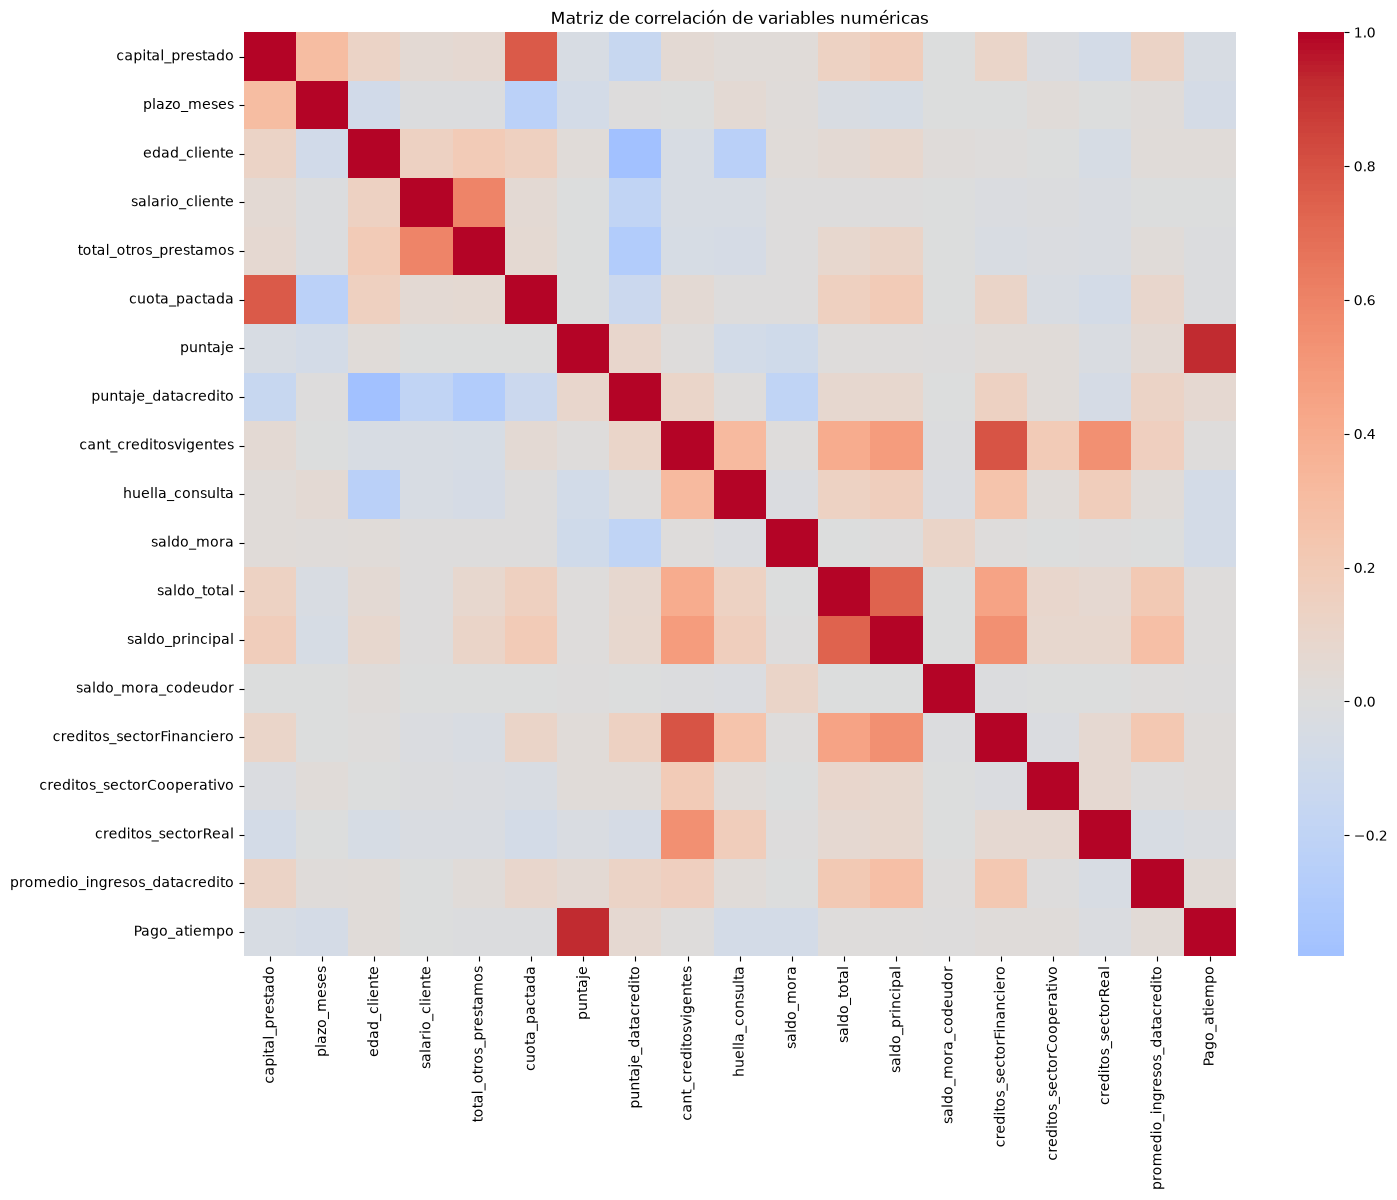

In [26]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    matriz_correlacion,
    cmap='coolwarm',
    center=0,
    annot=False
)

plt.title('Matriz de correlación de variables numéricas')
plt.show()

In [27]:
pares_correlacion = (
    matriz_correlacion
    .where(np.triu(np.ones(matriz_correlacion.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

pares_correlacion.head(15)

puntaje                Pago_atiempo                     0.923134
cant_creditosvigentes  creditos_sectorFinanciero        0.791253
capital_prestado       cuota_pactada                    0.764104
saldo_total            saldo_principal                  0.734664
salario_cliente        total_otros_prestamos            0.596990
cant_creditosvigentes  creditos_sectorReal              0.540677
saldo_principal        creditos_sectorFinanciero        0.537307
cant_creditosvigentes  saldo_principal                  0.485953
saldo_total            creditos_sectorFinanciero        0.451957
cant_creditosvigentes  saldo_total                      0.402105
edad_cliente           puntaje_datacredito             -0.380759
cant_creditosvigentes  huella_consulta                  0.317554
capital_prestado       plazo_meses                      0.299781
saldo_principal        promedio_ingresos_datacredito    0.287729
total_otros_prestamos  puntaje_datacredito             -0.283266
dtype: float64

Al revisar la matriz de correlación se observan algunas relaciones altas entre variables. La más fuerte aparece entre `puntaje` y `Pago_atiempo`, con una correlación de 0.923, por lo que es importante revisar cómo se construye la variable `puntaje` y confirmar que no contenga información relacionada directamente con la variable objetivo.

También se observan relaciones altas entre `cant_creditosvigentes` y `creditos_sectorFinanciero` (0.791), `capital_prestado` y `cuota_pactada` (0.764), y `saldo_total` y `saldo_principal` (0.735). Estas relaciones pueden indicar que algunas variables contienen información similar, pero por ahora no se eliminará ninguna sin revisar primero su significado y utilidad para el modelo.

### Revisión de variables irrelevantes o redundantes

Durante el análisis no se identificaron variables que puedan considerarse claramente irrelevantes únicamente por su significado o comportamiento en los datos. Tampoco se encontraron columnas identificadoras que deban eliminarse directamente.

La matriz de correlación mostró relaciones altas entre `cant_creditosvigentes` y `creditos_sectorFinanciero`, `capital_prestado` y `cuota_pactada`, y `saldo_total` y `saldo_principal`. Sin embargo, estas variables representan conceptos diferentes dentro del crédito, por lo que una correlación alta no es suficiente para eliminar alguna de ellas en esta etapa.

`fecha_prestamo` también requiere una consideración especial. Aunque la fecha exacta probablemente no se utilice directamente como entrada del modelo, puede servir posteriormente para obtener características temporales como año o mes, por lo que se conserva durante esta etapa.

Por otro lado, `puntaje` presenta una relación especialmente alta con `Pago_atiempo`. Antes de utilizar esta variable será necesario conocer cómo fue construida. Si se comprueba que utiliza información relacionada directamente con el resultado de pago, deberá excluirse para evitar fuga de información.

Por estas razones, en esta etapa no se eliminan variables. La decisión se toma de forma consciente a partir del análisis realizado y las variables que requieren revisión quedan identificadas para las siguientes etapas.

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  int64         
 1   fecha_prestamo                 10763 non-null  datetime64[us]
 2   capital_prestado               10763 non-null  int64         
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  str           
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11  cant_creditosvigentes     

In [29]:
df.isnull().sum()

tipo_credito                        0
fecha_prestamo                      0
capital_prestado                    0
plazo_meses                         0
edad_cliente                        0
tipo_laboral                        0
salario_cliente                     0
total_otros_prestamos               0
cuota_pactada                       0
puntaje                             0
puntaje_datacredito                 6
cant_creditosvigentes               0
huella_consulta                     0
saldo_mora                        156
saldo_total                       156
saldo_principal                   405
saldo_mora_codeudor               590
creditos_sectorFinanciero           0
creditos_sectorCooperativo          0
creditos_sectorReal                 0
promedio_ingresos_datacredito    2930
tendencia_ingresos               2990
Pago_atiempo                        0
dtype: int64

Después de los ajustes realizados se volvió a revisar la estructura de la base. `fecha_prestamo` ya quedó reconocida como fecha y `puntaje` como variable numérica. También se confirmó que los valores inconsistentes encontrados en `tendencia_ingresos` quedaron representados como nulosy todavía existen datos faltantes en algunas variables.

In [84]:
valores_nulos_texto = ['', ' ', 'NA', 'N/A', 'null', 'NULL', 'None', 'nan']

for columna in df.select_dtypes(include=['object', 'string']).columns:
    encontrados = df[columna].isin(valores_nulos_texto).sum()
    if encontrados > 0:
        print(f'{columna}: {encontrados}')

### Unificación de la representación de valores nulos

Se revisó si existían diferentes formas de representar valores faltantes dentro de las variables de texto. Además, en `tendencia_ingresos` se habían identificado 58 valores que no correspondían a las categorías esperadas (`Decreciente`, `Estable` y `Creciente`), por lo que fueron reemplazados por `NaN`.

De esta manera, los datos faltantes identificados durante esta etapa quedan representados como valores nulos reconocibles por pandas, facilitando su análisis y posterior tratamiento.

In [30]:
df['tipo_credito'] = df['tipo_credito'].astype('category')

df['tipo_laboral'] = df['tipo_laboral'].astype('category')

df['Pago_atiempo'] = df['Pago_atiempo'].astype('category')

In [31]:
orden_tendencia = ['Decreciente', 'Estable', 'Creciente']

df['tendencia_ingresos'] = pd.Categorical(
    df['tendencia_ingresos'],
    categories=orden_tendencia,
    ordered=True
)

In [32]:
df[
    ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos', 'Pago_atiempo']
].dtypes

tipo_credito          category
tipo_laboral          category
tendencia_ingresos    category
Pago_atiempo          category
dtype: object

Se ajustaron las variables que representan categorías para que quedaran almacenadas como tipo `category`. También se definió un orden para `tendencia_ingresos` (`Decreciente`, `Estable`, `Creciente`), ya que estas categorías sí tienen una secuencia lógica. Con esto, los tipos de datos quedan más acordes con el significado real de cada variable.

Análisis univariable

In [33]:
variables_numericas = [
    'capital_prestado',
    'plazo_meses',
    'edad_cliente',
    'salario_cliente',
    'total_otros_prestamos',
    'cuota_pactada',
    'puntaje',
    'puntaje_datacredito',
    'cant_creditosvigentes',
    'huella_consulta',
    'saldo_mora',
    'saldo_total',
    'saldo_principal',
    'saldo_mora_codeudor',
    'creditos_sectorFinanciero',
    'creditos_sectorCooperativo',
    'creditos_sectorReal',
    'promedio_ingresos_datacredito'
]

In [34]:
df[variables_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
capital_prestado,10763.0,2.434315e+06,1.909643e+06,360000.00000,1.224831e+06,1.921920e+06,3.084840e+06,4.144415e+07
plazo_meses,10763.0,1.057558e+01,6.632082e+00,2.00000,6.000000e+00,1.000000e+01,1.200000e+01,9.000000e+01
edad_cliente,10763.0,4.394862e+01,1.506088e+01,19.00000,3.300000e+01,4.200000e+01,5.300000e+01,1.230000e+02
salario_cliente,10763.0,1.721643e+07,3.554767e+08,0.00000,2.000000e+06,3.000000e+06,4.875808e+06,2.200000e+10
total_otros_prestamos,10763.0,6.238870e+06,1.184183e+08,0.00000,5.000000e+05,1.000000e+06,2.000000e+06,6.787675e+09
cuota_pactada,10763.0,2.436174e+05,2.104937e+05,23944.00000,1.210415e+05,1.828630e+05,2.878335e+05,3.816752e+06
puntaje,10763.0,9.117004e+01,1.646544e+01,-38.00999,9.522779e+01,9.522779e+01,9.522779e+01,9.522779e+01
puntaje_datacredito,10757.0,7.807908e+02,1.048780e+02,-7.00000,7.570000e+02,7.910000e+02,8.250000e+02,9.990000e+02
cant_creditosvigentes,10763.0,5.726749e+00,3.977162e+00,0.00000,3.000000e+00,5.000000e+00,8.000000e+00,6.200000e+01
huella_consulta,10763.0,4.228561e+00,3.064683e+00,0.00000,2.000000e+00,4.000000e+00,6.000000e+00,2.900000e+01


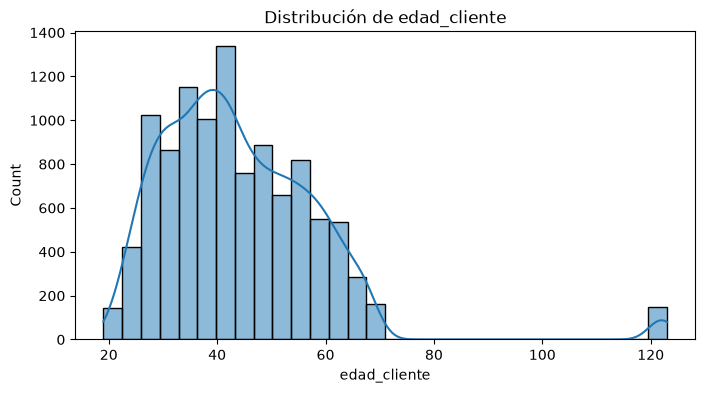

In [35]:
plt.figure(figsize=(8,4))
sns.histplot(df['edad_cliente'], bins=30, kde=True)
plt.title('Distribución de edad_cliente')
plt.show()

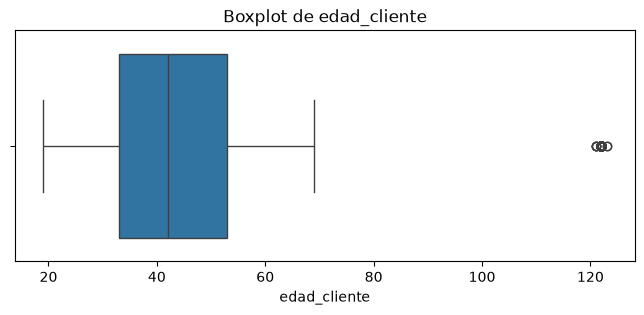

In [36]:
plt.figure(figsize=(8,3))
sns.boxplot(x=df['edad_cliente'])
plt.title('Boxplot de edad_cliente')
plt.show()

La variable `edad_cliente` se concentra principalmente entre los 20 y 70 años, con una mediana de 42 años. Sin embargo, tanto el histograma como el boxplot muestran algunos valores cercanos a 120 años, y el valor máximo registrado es 123. Estos datos se comportan como valores atípicos.

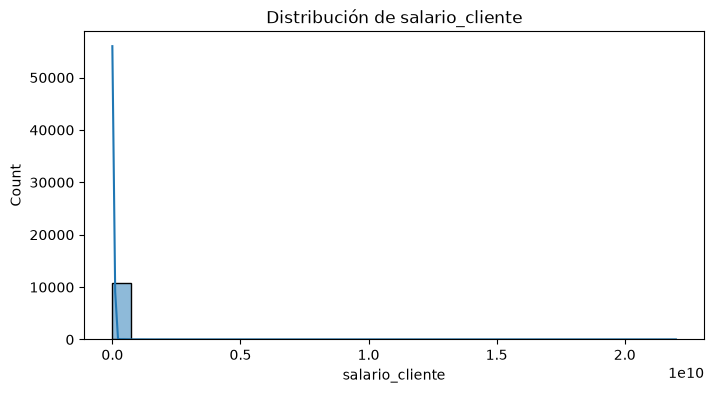

In [37]:
plt.figure(figsize=(8,4))
sns.histplot(df['salario_cliente'], bins=30, kde=True)
plt.title('Distribución de salario_cliente')
plt.show()

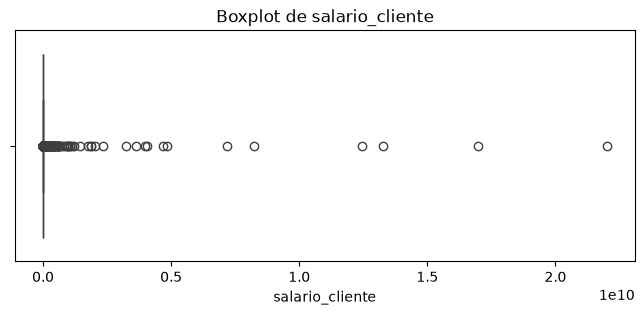

In [38]:
plt.figure(figsize=(8,3))
sns.boxplot(x=df['salario_cliente'])
plt.title('Boxplot de salario_cliente')
plt.show()

En `salario_cliente` se observa que la mayoría de los valores se concentran en la parte baja de la distribución, mientras que existen algunos registros con salarios mucho más altos que el resto. Esto hace que la distribución quede muy extendida hacia la derecha y que en el boxplot aparezcan varios valores atípicos. 

In [50]:
resumen_numerico = pd.DataFrame({
    'media': df[variables_numericas].mean(),
    'mediana': df[variables_numericas].median(),
    'moda': df[variables_numericas].mode().iloc[0],
    'minimo': df[variables_numericas].min(),
    'Q1_25%': df[variables_numericas].quantile(0.25),
    'Q3_75%': df[variables_numericas].quantile(0.75),
    'maximo': df[variables_numericas].max(),
    'rango': df[variables_numericas].max() - df[variables_numericas].min(),
    'IQR': df[variables_numericas].quantile(0.75) - df[variables_numericas].quantile(0.25),
    'varianza': df[variables_numericas].var(),
    'desviacion_estandar': df[variables_numericas].std(),
    'skewness': df[variables_numericas].skew(),
    'kurtosis': df[variables_numericas].kurt()
})

resumen_numerico.round(2)

,media,mediana,moda,minimo,Q1_25%,Q3_75%,maximo,rango,IQR,varianza,desviacion_estandar,skewness,kurtosis
capital_prestado,2434315.00,1921920.00,1200000.00,360000.00,1224831.00,3084840.00,4.144415e+07,4.108415e+07,1860009.00,3.646735e+12,1.909643e+06,3.72,35.32
plazo_meses,10.58,10.00,6.00,2.00,6.00,12.00,9.000000e+01,8.800000e+01,6.00,4.398000e+01,6.630000e+00,2.46,7.78
edad_cliente,43.95,42.00,40.00,19.00,33.00,53.00,1.230000e+02,1.040000e+02,20.00,2.268300e+02,1.506000e+01,1.93,7.87
salario_cliente,17216431.46,3000000.00,3000000.00,0.00,2000000.00,4875808.00,2.200000e+10,2.200000e+10,2875808.00,1.263637e+17,3.554767e+08,43.78,2211.23
total_otros_prestamos,6238869.65,1000000.00,2000000.00,0.00,500000.00,2000000.00,6.787675e+09,6.787675e+09,1500000.00,1.402290e+16,1.184183e+08,38.46,1719.28
cuota_pactada,243617.41,182863.00,205990.00,23944.00,121041.50,287833.50,3.816752e+06,3.792808e+06,166792.00,4.430760e+10,2.104937e+05,3.79,26.65
puntaje,91.17,95.23,95.23,-38.01,95.23,95.23,9.523000e+01,1.332400e+02,0.00,2.711100e+02,1.647000e+01,-4.87,24.08
puntaje_datacredito,780.79,791.00,0.00,-7.00,757.00,825.00,9.990000e+02,1.006000e+03,68.00,1.099940e+04,1.048800e+02,-5.64,39.44
cant_creditosvigentes,5.73,5.00,4.00,0.00,3.00,8.00,6.200000e+01,6.200000e+01,5.00,1.582000e+01,3.980000e+00,1.80,8.62
huella_consulta,4.23,4.00,2.00,0.00,2.00,6.00,2.900000e+01,2.900000e+01,4.00,9.390000e+00,3.060000e+00,1.49,4.00


Al revisar las estadísticas de las variables numéricas se observan varias distribuciones con valores muy alejados de sus valores centrales. Variables como `total_otros_prestamos`, `saldo_mora`, `saldo_total` y `saldo_mora_codeudor` presentan niveles altos de asimetría y curtosis, lo que indica la presencia de valores extremos. También llaman la atención `puntaje` y `puntaje_datacredito`, ya que presentan asimetría negativa y valores mínimos por debajo de cero.

### Forma de las distribuciones

A partir de las medidas de asimetría y curtosis, y de los histogramas analizados posteriormente, se observa que varias variables numéricas no presentan una distribución simétrica. Variables como `salario_cliente`, `total_otros_prestamos`, `saldo_mora`, `saldo_total` y `saldo_mora_codeudor` presentan una fuerte asimetría hacia la derecha, debido a la concentración de valores bajos y la presencia de algunos valores mucho más altos.

Por otro lado, `puntaje` y `puntaje_datacredito` presentan asimetría negativa, ya que la mayor parte de sus valores se concentra en la zona alta de la distribución y existen algunos registros considerablemente menores.

Con estos resultados no se observa un comportamiento cercano a una distribución normal en estas variables, por lo que cualquier transformación que se considere más adelante deberá evaluarse de acuerdo con las características de cada una.

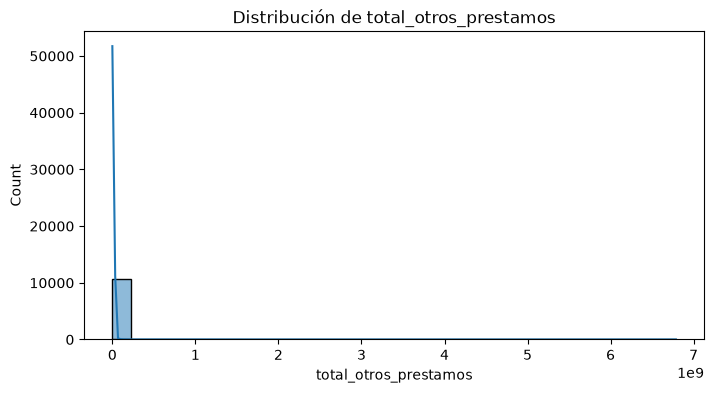

In [41]:
plt.figure(figsize=(8,4))
sns.histplot(df['total_otros_prestamos'], bins=30, kde=True)
plt.title('Distribución de total_otros_prestamos')
plt.show()

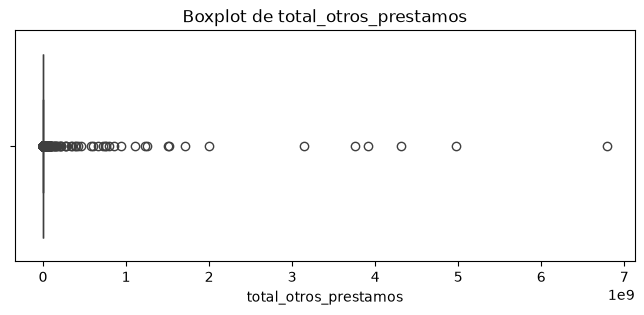

In [42]:
plt.figure(figsize=(8,3))
sns.boxplot(x=df['total_otros_prestamos'])
plt.title('Boxplot de total_otros_prestamos')
plt.show()

En `total_otros_prestamos` se observa que la mayoría de los valores se concentra en montos bajos, mientras que algunos registros tienen valores mucho más altos que el resto. Esto genera una distribución muy extendida hacia la derecha y varios valores atípicos en el boxplot. 

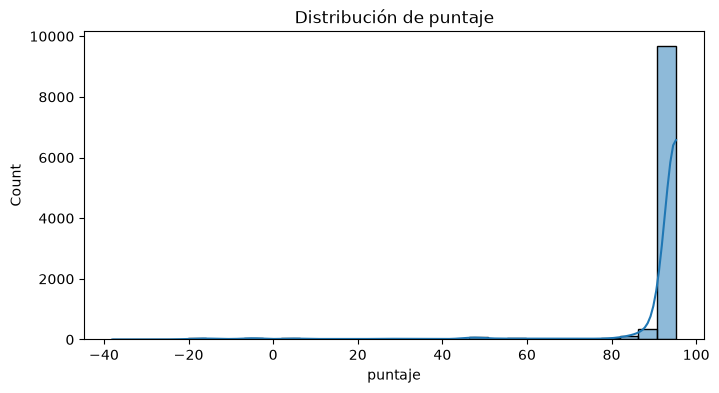

In [43]:
plt.figure(figsize=(8,4))
sns.histplot(df['puntaje'], bins=30, kde=True)
plt.title('Distribución de puntaje')
plt.show()

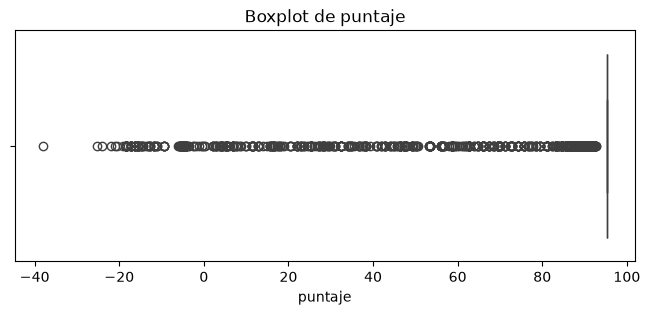

In [44]:
plt.figure(figsize=(8,3))
sns.boxplot(x=df['puntaje'])
plt.title('Boxplot de puntaje')
plt.show()

En `puntaje` se observa una concentración muy marcada alrededor de 95, mientras que una cantidad menor de registros presenta valores más bajos e incluso negativos. La mediana y los cuartiles son prácticamente iguales, por lo que el IQR es 0 y el boxplot termina marcando muchos de los valores diferentes como atípicos. Por esta razón, estos puntos no deben eliminarse automáticamente y es necesario revisar primero qué representa esta variable y cómo fue calculada.

In [45]:
pd.crosstab(
    df['puntaje'].round(2),
    df['Pago_atiempo']
).sort_index(ascending=False).head(15)

Pago_atiempo,0,1
puntaje,,
95.23,0,9407
92.76,0,1
92.60,0,1
92.43,0,14
92.23,0,51
92.00,0,73
91.73,0,56
91.41,0,45
91.03,0,25


Al comparar `puntaje` con `Pago_atiempo` se observa que los valores de puntaje más altos aparecen únicamente en registros con pago a tiempo. Esto confirma que existe una relación fuerte entre ambas variables.

In [46]:
pd.crosstab(
    df['puntaje'].round(2),
    df['Pago_atiempo']
).sort_index().head(15)

Pago_atiempo,0,1
puntaje,,
-38.01,1,0
-25.21,1,0
-24.04,1,0
-21.86,1,0
-21.10,1,0
-20.63,1,0
-19.00,1,0
-18.47,16,0
-17.88,1,0


In [47]:
df.groupby('Pago_atiempo', observed=True)['puntaje'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
Pago_atiempo,,,,,
0,511,23.091216,25.419455,-38.009990,62.667613
1,10252,94.563352,95.227787,63.809656,95.227787


Al comparar `puntaje` con `Pago_atiempo` se observa una separación muy marcada entre los dos grupos. Los registros que no pagan a tiempo presentan puntajes considerablemente más bajos, mientras que los registros con pago a tiempo tienen puntajes altos. Esta diferencia explica la fuerte relación encontrada anteriormente entre ambas variables.

Observación: Debido a la separación tan marcada entre puntaje y la variable objetivo, será importante verificar el origen de puntaje antes del entrenamiento para descartar que haya sido calculado usando información relacionada con el resultado final.

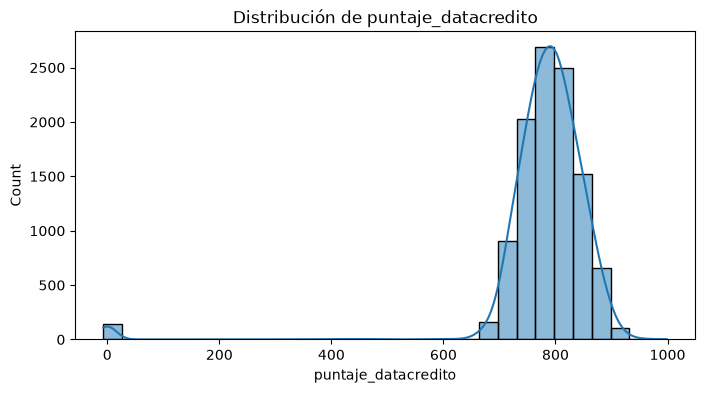

In [48]:
plt.figure(figsize=(8,4))
sns.histplot(df['puntaje_datacredito'].dropna(), bins=30, kde=True)
plt.title('Distribución de puntaje_datacredito')
plt.show()

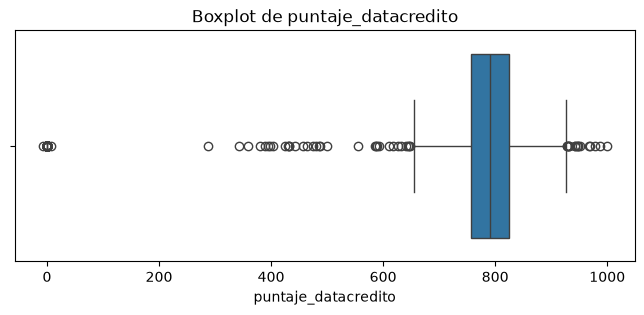

In [49]:
plt.figure(figsize=(8,3))
sns.boxplot(x=df['puntaje_datacredito'].dropna())
plt.title('Boxplot de puntaje_datacredito')
plt.show()

En `puntaje_datacredito` la mayoría de los registros se concentra en valores altos, principalmente entre 700 y 900 pero también aparecen algunos valores mucho más bajos que el resto, incluso cercanos a cero y negativos, los cuales se observan como atípicos en el boxplot.


análisis univariable de las variables categóricas.

In [51]:
df['tipo_credito'].value_counts()

tipo_credito
4     7747
9     2876
10     116
6       21
7        2
68       1
Name: count, dtype: int64

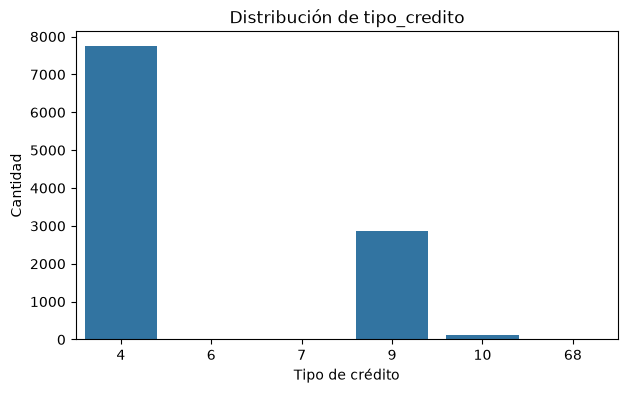

In [52]:
plt.figure(figsize=(7,4))
sns.countplot(x=df['tipo_credito'])
plt.title('Distribución de tipo_credito')
plt.xlabel('Tipo de crédito')
plt.ylabel('Cantidad')
plt.show()

En `tipo_credito` la mayoría de los registros se concentra en los códigos 4 y 9. Las demás categorías aparecen con una frecuencia mucho menor.

In [53]:
df['tipo_laboral'].value_counts()

tipo_laboral
Empleado         6754
Independiente    4009
Name: count, dtype: int64

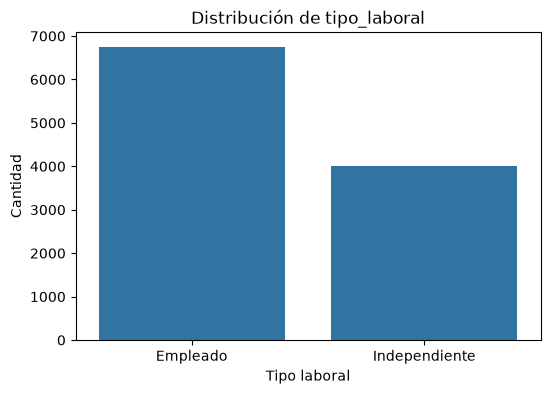

In [54]:
plt.figure(figsize=(6,4))
sns.countplot(x=df['tipo_laboral'])
plt.title('Distribución de tipo_laboral')
plt.xlabel('Tipo laboral')
plt.ylabel('Cantidad')
plt.show()

En `tipo_laboral` se observa una mayor cantidad de clientes empleados que independientes. Aun así, ambas categorías tienen una presencia importante dentro de la base.

In [55]:
df['tendencia_ingresos'].value_counts(dropna=False)

tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64

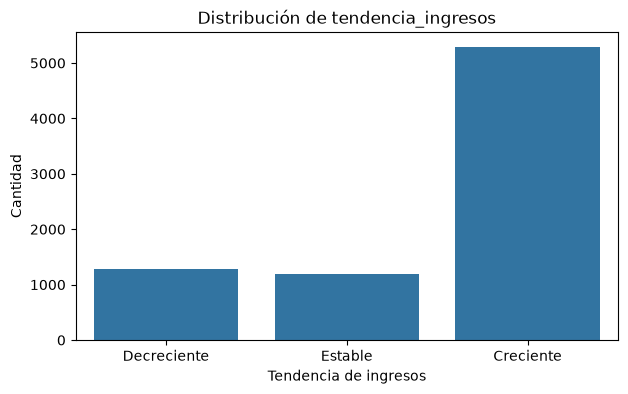

In [56]:
plt.figure(figsize=(7,4))
sns.countplot(x=df['tendencia_ingresos'])
plt.title('Distribución de tendencia_ingresos')
plt.xlabel('Tendencia de ingresos')
plt.ylabel('Cantidad')
plt.show()

En `tendencia_ingresos` la categoría más frecuente es `Creciente`, mientras que `Decreciente` y `Estable` presentan cantidades similares. También se observa una cantidad importante de valores nulos, que ya habían sido identificados durante la limpieza inicial.

In [57]:
df['Pago_atiempo'].value_counts()

Pago_atiempo
1    10252
0      511
Name: count, dtype: int64

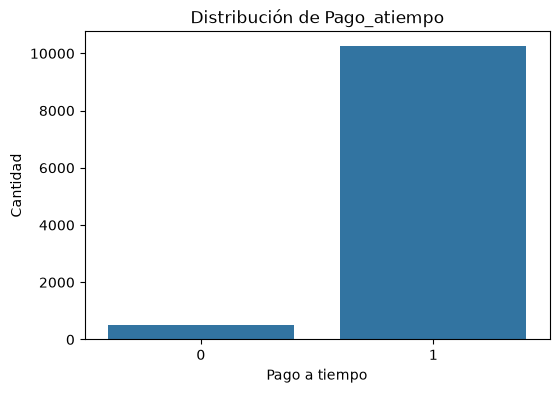

In [58]:
plt.figure(figsize=(6,4))
sns.countplot(x=df['Pago_atiempo'])
plt.title('Distribución de Pago_atiempo')
plt.xlabel('Pago a tiempo')
plt.ylabel('Cantidad')
plt.show()

En `Pago_atiempo` se observa un desbalance marcado entre las dos categorías. La clase 1 concentra 10.252 registros, mientras que la clase 0 tiene 511. Esto muestra que la variable objetivo no está distribuida de manera equilibrada.

análisis bivariable

In [59]:
tabla_tipo_credito = pd.crosstab(
    df['tipo_credito'],
    df['Pago_atiempo'],
    normalize='index'
) * 100

tabla_tipo_credito.round(2)

Pago_atiempo,0,1
tipo_credito,,
4,4.69,95.31
6,42.86,57.14
7,0.00,100.00
9,4.73,95.27
10,2.59,97.41
68,0.00,100.00


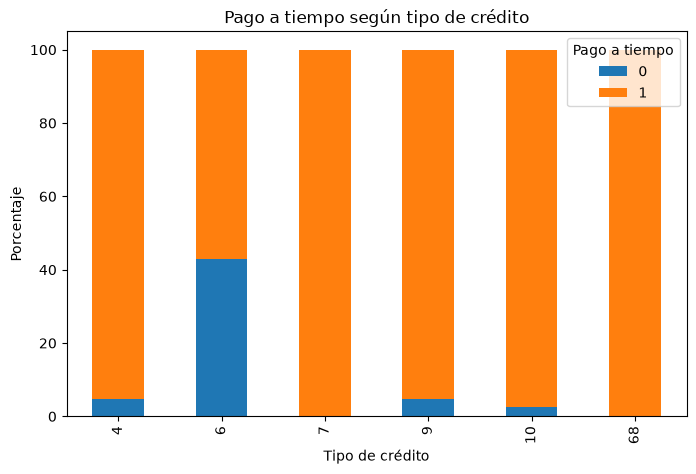

In [60]:
tabla_tipo_credito.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5)
)

plt.title('Pago a tiempo según tipo de crédito')
plt.xlabel('Tipo de crédito')
plt.ylabel('Porcentaje')
plt.legend(title='Pago a tiempo')
plt.show()

El tipo de crédito 6 presenta el porcentaje más alto de pagos no realizados a tiempo, con 42,86 %. Sin embargo, este resultado corresponde únicamente a 21 registros, por lo que debe interpretarse con cuidado. En cambio, los tipos 4 y 9 concentran la mayor cantidad de datos y presentan porcentajes muy similares de no pago a tiempo, alrededor del 4,7 %.

In [61]:
resumen_tipo_credito = pd.DataFrame({
    'total_registros': df.groupby('tipo_credito', observed=True).size(),
    'no_pago_a_tiempo': df[df['Pago_atiempo'] == 0]
        .groupby('tipo_credito', observed=True).size()
}).fillna(0)

resumen_tipo_credito['porcentaje_no_pago'] = (
    resumen_tipo_credito['no_pago_a_tiempo']
    / resumen_tipo_credito['total_registros'] * 100
)

resumen_tipo_credito.round(2)

,total_registros,no_pago_a_tiempo,porcentaje_no_pago
tipo_credito,,,
4,7747,363.0,4.69
6,21,9.0,42.86
7,2,0.0,0.00
9,2876,136.0,4.73
10,116,3.0,2.59
68,1,0.0,0.00


In [62]:
tabla_tipo_laboral = pd.crosstab(
    df['tipo_laboral'],
    df['Pago_atiempo'],
    normalize='index'
) * 100

tabla_tipo_laboral.round(2)

Pago_atiempo,0,1
tipo_laboral,,
Empleado,4.29,95.71
Independiente,5.51,94.49


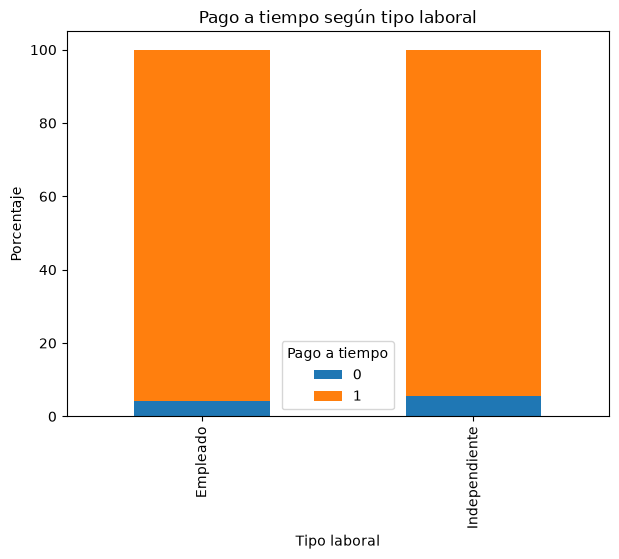

In [63]:
tabla_tipo_laboral.plot(
    kind='bar',
    stacked=True,
    figsize=(7,5)
)

plt.title('Pago a tiempo según tipo laboral')
plt.xlabel('Tipo laboral')
plt.ylabel('Porcentaje')
plt.legend(title='Pago a tiempo')
plt.show()

Al comparar `tipo_laboral` con `Pago_atiempo`, los clientes independientes presentan una proporción de no pago de 5,51 %, mientras que en los empleados es de 4,29 %. La diferencia entre ambos grupos es de 1,22 puntos porcentuales, por lo que el comportamiento es bastante similar.

In [64]:
tabla_tendencia = pd.crosstab(
    df['tendencia_ingresos'],
    df['Pago_atiempo'],
    normalize='index'
) * 100

tabla_tendencia.round(2)

Pago_atiempo,0,1
tendencia_ingresos,,
Decreciente,6.27,93.73
Estable,4.63,95.37
Creciente,3.91,96.09


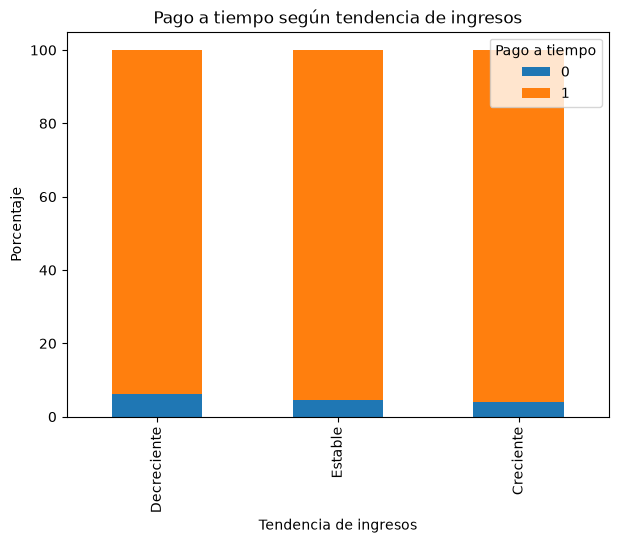

In [65]:
tabla_tendencia.plot(
    kind='bar',
    stacked=True,
    figsize=(7,5)
)

plt.title('Pago a tiempo según tendencia de ingresos')
plt.xlabel('Tendencia de ingresos')
plt.ylabel('Porcentaje')
plt.legend(title='Pago a tiempo')
plt.show()

Al comparar `tendencia_ingresos` con `Pago_atiempo`, los clientes con ingresos decrecientes presentan la mayor proporción de no pago, con 6,27 %. En los ingresos estables esta proporción baja a 4,63 % y en los crecientes a 3,91 %. Se observa que el porcentaje de no pago disminuye a medida que la tendencia de los ingresos pasa de decreciente a estable y luego a creciente.

In [66]:
df.groupby('Pago_atiempo', observed=True)['puntaje_datacredito'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
Pago_atiempo,,,,,
0,510,748.880392,768.0,0.0,922.0
1,10247,782.379038,792.0,-7.0,999.0


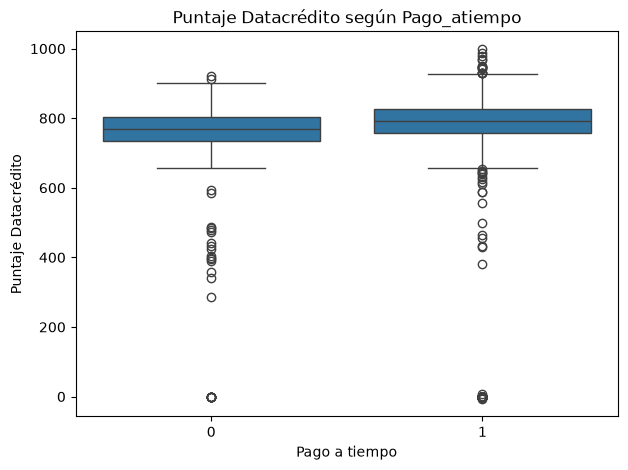

In [67]:
plt.figure(figsize=(7,5))
sns.boxplot(
    x='Pago_atiempo',
    y='puntaje_datacredito',
    data=df
)
plt.title('Puntaje Datacrédito según Pago_atiempo')
plt.xlabel('Pago a tiempo')
plt.ylabel('Puntaje Datacrédito')
plt.show()

Al comparar `puntaje_datacredito` con `Pago_atiempo`, los clientes que pagan a tiempo presentan valores ligeramente más altos. La mediana es de 792 para quienes pagan a tiempo y de 768 para quienes no lo hacen. Aunque existe una diferencia entre ambos grupos, sus distribuciones todavía presentan bastante solapamiento.

In [68]:
df.groupby('Pago_atiempo', observed=True)['salario_cliente'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
Pago_atiempo,,,,,
0,511,2.355514e+07,3000000.0,0,4663274549
1,10252,1.690049e+07,3000000.0,0,22000000000


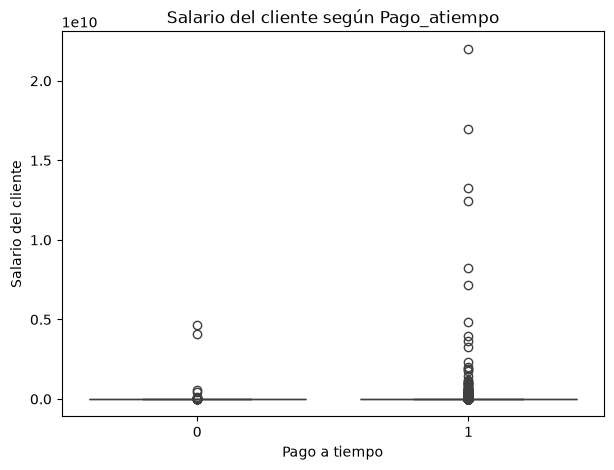

In [69]:
plt.figure(figsize=(7,5))
sns.boxplot(
    x='Pago_atiempo',
    y='salario_cliente',
    data=df
)
plt.title('Salario del cliente según Pago_atiempo')
plt.xlabel('Pago a tiempo')
plt.ylabel('Salario del cliente')
plt.show()

Al comparar `salario_cliente` con `Pago_atiempo`, ambos grupos presentan una mediana de 3.000.000. Aunque las medias son diferentes, estas se ven afectadas por varios salarios extremadamente altos. En el boxplot no se observa una separación clara entre quienes pagan a tiempo y quienes no.

In [70]:
df.groupby('Pago_atiempo', observed=True)['capital_prestado'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
Pago_atiempo,,,,,
0,511,2.781774e+06,2268000.0,408000,11808000
1,10252,2.416996e+06,1908446.5,360000,41444153


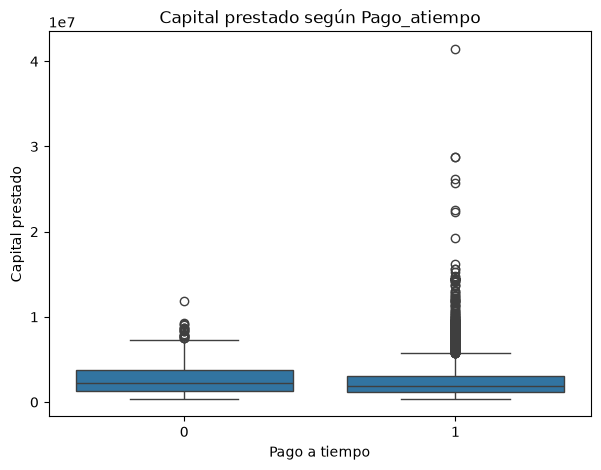

In [71]:
plt.figure(figsize=(7,5))
sns.boxplot(
    x='Pago_atiempo',
    y='capital_prestado',
    data=df
)
plt.title('Capital prestado según Pago_atiempo')
plt.xlabel('Pago a tiempo')
plt.ylabel('Capital prestado')
plt.show()

Al comparar `capital_prestado` con `Pago_atiempo`, los clientes que no pagan a tiempo presentan una media y una mediana de capital prestado ligeramente mayores y las distribuciones de ambos grupos se superponen bastante, por lo que esta variable no muestra una separación clara entre las dos clases.


In [72]:
df.groupby('Pago_atiempo', observed=True)['total_otros_prestamos'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
Pago_atiempo,,,,,
0,511,1.156440e+07,900000.0,0,3918433000
1,10252,5.973424e+06,1000000.0,0,6787675263


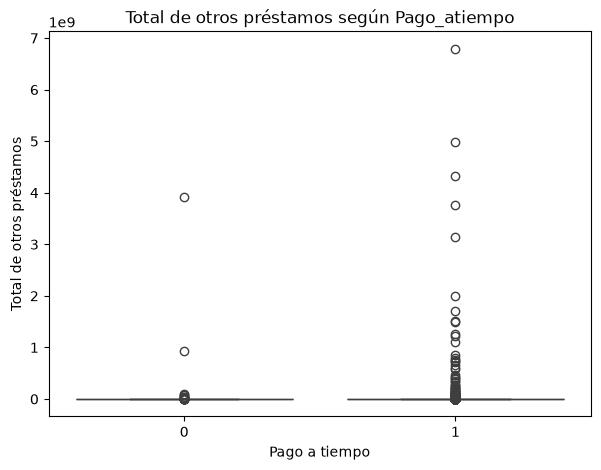

In [73]:
plt.figure(figsize=(7,5))
sns.boxplot(
    x='Pago_atiempo',
    y='total_otros_prestamos',
    data=df
)
plt.title('Total de otros préstamos según Pago_atiempo')
plt.xlabel('Pago a tiempo')
plt.ylabel('Total de otros préstamos')
plt.show()

Al comparar `total_otros_prestamos` con `Pago_atiempo`, la media es mayor en los clientes que no pagan a tiempo, pero la mediana es muy similar entre ambos grupos. Esta diferencia entre media y mediana se debe a la presencia de valores extremos, por lo que no se observa una separación clara entre las dos clases.

análisis multivariable

In [74]:
tabla_multivariable = (
    df.groupby(
        ['tipo_laboral', 'tendencia_ingresos'],
        observed=True
    )['Pago_atiempo']
    .apply(lambda x: (x == 0).mean() * 100)
    .unstack()
)

tabla_multivariable.round(2)

tendencia_ingresos,Decreciente,Estable,Creciente
tipo_laboral,,,
Empleado,5.87,4.49,3.56
Independiente,7.34,4.80,4.82


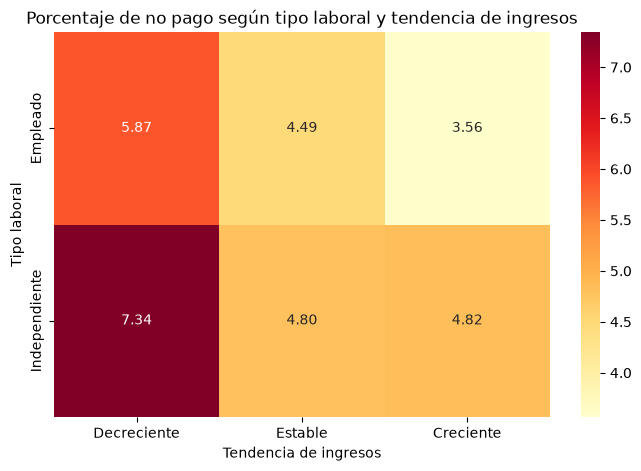

In [75]:
plt.figure(figsize=(8,5))

sns.heatmap(
    tabla_multivariable,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd'
)

plt.title('Porcentaje de no pago según tipo laboral y tendencia de ingresos')
plt.xlabel('Tendencia de ingresos')
plt.ylabel('Tipo laboral')
plt.show()

In [76]:
pd.crosstab(
    df['tipo_laboral'],
    df['tendencia_ingresos']
)

tendencia_ingresos,Decreciente,Estable,Creciente
tipo_laboral,,,
Empleado,937,646,3843
Independiente,354,542,1451


Al combinar `tipo_laboral` y `tendencia_ingresos` se observa que los clientes con ingresos decrecientes presentan los mayores porcentajes de no pago en ambos grupos laborales. La combinación con mayor proporción corresponde a los clientes independientes con ingresos decrecientes, con 7,34 %. Además, esta combinación cuenta con 354 registros, por lo que el resultado no corresponde a una categoría con muy pocos casos.

In [77]:
tabla_credito_tendencia = (
    df.groupby(
        ['tipo_credito', 'tendencia_ingresos'],
        observed=True
    )['Pago_atiempo']
    .apply(lambda x: (x == 0).mean() * 100)
    .unstack()
)

tabla_credito_tendencia.round(2)

tendencia_ingresos,Decreciente,Estable,Creciente
tipo_credito,,,
4,6.04,4.44,3.94
6,0.00,NaN,50.00
7,NaN,0.00,NaN
9,6.99,4.81,3.52
10,11.11,11.76,0.00
68,NaN,NaN,0.00


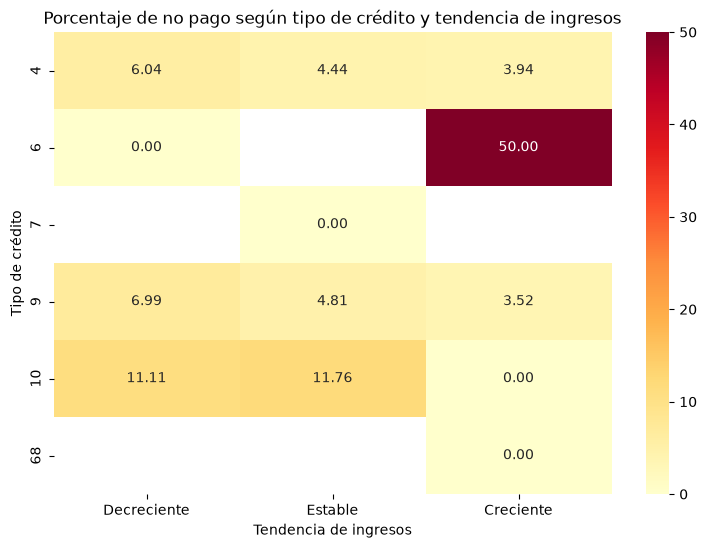

In [78]:
plt.figure(figsize=(9,6))

sns.heatmap(
    tabla_credito_tendencia,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd'
)

plt.title('Porcentaje de no pago según tipo de crédito y tendencia de ingresos')
plt.xlabel('Tendencia de ingresos')
plt.ylabel('Tipo de crédito')
plt.show()

In [79]:
pd.crosstab(
    df['tipo_credito'],
    df['tendencia_ingresos']
)

tendencia_ingresos,Decreciente,Estable,Creciente
tipo_credito,,,
4,993,900,3855
6,3,0,14
7,0,1,0
9,286,270,1363
10,9,17,61
68,0,0,1


En los tipos de crédito 4 y 9, que concentran la mayor cantidad de registros, se observa el mismo comportamiento: el porcentaje de no pago es mayor cuando los ingresos son decrecientes y disminuye cuando pasan a estables o crecientes. En los demás tipos de crédito hay combinaciones con pocos registros, por lo que sus porcentajes deben interpretarse con más cuidado.

In [80]:
tabla_datacredito_tendencia = df.groupby(
    ['tendencia_ingresos', 'Pago_atiempo'],
    observed=True
)['puntaje_datacredito'].median().unstack()

tabla_datacredito_tendencia.round(2)

Pago_atiempo,0,1
tendencia_ingresos,,
Decreciente,762.0,791.0
Estable,772.0,797.0
Creciente,763.0,791.0


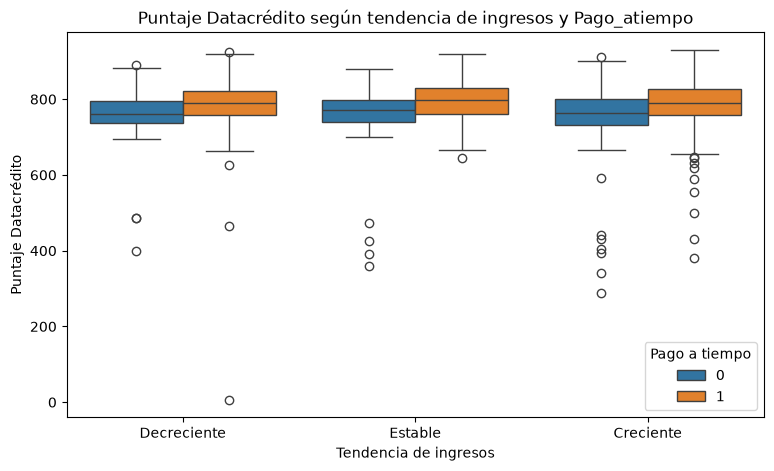

In [81]:
plt.figure(figsize=(9,5))

sns.boxplot(
    x='tendencia_ingresos',
    y='puntaje_datacredito',
    hue='Pago_atiempo',
    data=df
)

plt.title('Puntaje Datacrédito según tendencia de ingresos y Pago_atiempo')
plt.xlabel('Tendencia de ingresos')
plt.ylabel('Puntaje Datacrédito')
plt.legend(title='Pago a tiempo')
plt.show()

En las tres categorías de `tendencia_ingresos`, los clientes que pagan a tiempo presentan medianas de `puntaje_datacredito` más altas que quienes no pagan a tiempo. Esta diferencia se mantiene tanto en ingresos decrecientes como estables y crecientes, aunque las distribuciones de ambos grupos continúan presentando solapamiento.

In [82]:
tabla_capital_laboral = df.groupby(
    ['tipo_laboral', 'Pago_atiempo'],
    observed=True
)['capital_prestado'].median().unstack()

tabla_capital_laboral.round(2)

Pago_atiempo,0,1
tipo_laboral,,
Empleado,2294111.0,1938540.0
Independiente,1999678.0,1865385.0


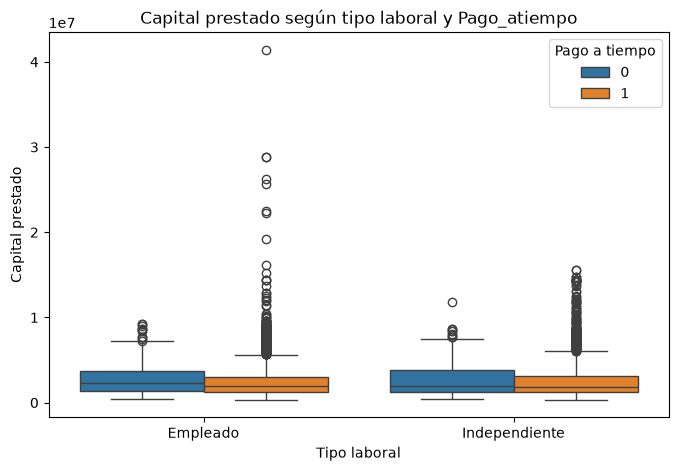

In [83]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='tipo_laboral',
    y='capital_prestado',
    hue='Pago_atiempo',
    data=df
)

plt.title('Capital prestado según tipo laboral y Pago_atiempo')
plt.xlabel('Tipo laboral')
plt.ylabel('Capital prestado')
plt.legend(title='Pago a tiempo')
plt.show()

Al analizar `capital_prestado` junto con `tipo_laboral` y `Pago_atiempo`, en empleados e independientes se observa que los clientes que no pagan a tiempo presentan medianas de capital prestado ligeramente mayores, aunque las distribuciones se superponen bastante, por lo que la diferencia entre los grupos no es marcada.

### Hallazgos principales del EDA

A partir del análisis exploratorio se identificaron varios comportamientos importantes dentro de la base de datos. La variable objetivo `Pago_atiempo` presenta un desbalance marcado, ya que la mayoría de los registros corresponde a clientes que sí pagan a tiempo.

También se encontraron valores extremos en variables como `salario_cliente`, `total_otros_prestamos`, `saldo_mora`, `saldo_total` y `saldo_mora_codeudor`, por lo que estas variables deben tratarse con cuidado en las siguientes etapas.

La variable `puntaje` mostró una relación muy fuerte con `Pago_atiempo`, llegando incluso a presentar una separación bastante marcada entre quienes pagan y quienes no. Por otro lado, `puntaje_datacredito` también presenta diferencias entre ambos grupos, aunque con mayor solapamiento.

En cuanto a `tendencia_ingresos`, se observó que los clientes con ingresos decrecientes presentan una mayor proporción de no pago que quienes tienen ingresos estables o crecientes. Este patrón también se mantiene en los tipos de crédito con mayor cantidad de registros.

Finalmente, algunas variables como `capital_prestado`, `salario_cliente` y `total_otros_prestamos` muestran diferencias entre los grupos de pago, pero estas no son tan marcadas y existe bastante superposición entre sus distribuciones.

Reglas de validación de los datos

In [85]:
df['edad_cliente'].describe()

count    10763.000000
mean        43.948620
std         15.060877
min         19.000000
25%         33.000000
50%         42.000000
75%         53.000000
max        123.000000
Name: edad_cliente, dtype: float64

In [86]:
df.loc[
    (df['edad_cliente'] < 18) | (df['edad_cliente'] > 100),
    ['edad_cliente']
].sort_values('edad_cliente')

,edad_cliente
10493,121
10533,121
10577,121
10611,121
10474,122
...,...
10619,122
10616,122
10617,122
10575,123


#### `edad_cliente`

La variable `edad_cliente` presenta edades entre 19 y 123 años. Al revisar los valores fuera del rango de 18 a 100 años se encontraron 150 registros, todos correspondientes a edades superiores a 100.

Debido a que se trata de varios registros y no de un único caso aislado, estos valores deben revisarse antes de asumir que son errores. Como regla de validación, se propone verificar que la edad se encuentre dentro del rango permitido por el negocio y marcar para revisión los registros que superen ese límite, en lugar de eliminarlos automáticamente.

In [87]:
df['puntaje_datacredito'].describe()

count    10757.000000
mean       780.790834
std        104.878031
min         -7.000000
25%        757.000000
50%        791.000000
75%        825.000000
max        999.000000
Name: puntaje_datacredito, dtype: float64

In [88]:
df.loc[
    (df['puntaje_datacredito'] < 0) | (df['puntaje_datacredito'] > 1000),
    ['puntaje_datacredito']
].sort_values('puntaje_datacredito')

,puntaje_datacredito
10208,-7.0


#### `puntaje_datacredito`

La variable `puntaje_datacredito` presenta valores entre -7 y 999, además de 6 registros con información faltante. Al revisar los valores fuera de un rango de 0 a 1000 se encontró un único registro con puntaje de -7 y no se identificaron valores superiores a 1000.

Como regla de validación, se propone verificar que los puntajes se encuentren entre 0 y 1000. Los valores negativos o superiores a este rango deberían marcarse para revisión y contrastarse con la definición de la fuente antes de decidir su tratamiento.

In [89]:
df['tipo_credito'].value_counts(dropna=False).sort_index()

tipo_credito
4     7747
6       21
7        2
9     2876
10     116
68       1
Name: count, dtype: int64

In [90]:
df['tipo_credito'].value_counts(dropna=False, normalize=True).mul(100).round(2)

tipo_credito
4     71.98
9     26.72
10     1.08
6      0.20
7      0.02
68     0.01
Name: proportion, dtype: float64

#### `tipo_credito`

La variable `tipo_credito` contiene los códigos 4, 6, 7, 9, 10 y 68. La mayor parte de los registros se concentra en los tipos 4 y 9, mientras que algunos códigos aparecen con muy poca frecuencia, como el 7 con 2 registros y el 68 con un solo registro.

Como regla de validación, se propone verificar que los valores de `tipo_credito` pertenezcan al catálogo oficial definido por el negocio. Los códigos poco frecuentes no deberían eliminarse automáticamente, pero sí revisarse para confirmar que corresponden a categorías válidas y no a errores de registro.

In [91]:
df['puntaje'].describe()

count    10763.000000
mean        91.170036
std         16.465441
min        -38.009990
25%         95.227787
50%         95.227787
75%         95.227787
max         95.227787
Name: puntaje, dtype: float64

In [92]:
df.loc[
    df['puntaje'] < 0,
    ['puntaje']
].sort_values('puntaje')

,puntaje
1158,-38.009990
10116,-25.210766
6831,-24.036161
10231,-21.864297
1563,-21.099465
...,...
7704,-2.348949
8147,-1.791725
7818,-1.123055
648,-0.522074


In [93]:
(df['puntaje'] < 0).sum()

np.int64(135)

#### `puntaje`

La variable `puntaje` presenta valores entre -38,01 y 95,23. Al revisar los valores negativos se encontraron 135 registros, por lo que no se trata de un único caso aislado. También se observa una fuerte concentración en el valor 95,227787, que coincide con el primer cuartil, la mediana y el tercer cuartil.

Como regla de validación, se propone verificar que los valores de `puntaje` se encuentren dentro del rango definido por la lógica con la que fue construida esta variable. Los valores negativos no deberían eliminarse automáticamente, sino revisarse para confirmar si son válidos dentro de su cálculo.

Debido a la relación especialmente alta encontrada entre `puntaje` y `Pago_atiempo`, será necesario revisar cómo se genera este puntaje antes de utilizarlo como variable predictora, con el fin de confirmar que no incluya información derivada directamente del resultado de pago.

In [94]:
df['Pago_atiempo'].value_counts(dropna=False)

Pago_atiempo
1    10252
0      511
Name: count, dtype: int64

In [96]:
df.loc[
    ~df['Pago_atiempo'].isin([0, 1]),
    ['Pago_atiempo']
]

,Pago_atiempo


#### `Pago_atiempo`

La variable `Pago_atiempo` está compuesta únicamente por los valores 0 y 1, con 10.252 registros correspondientes a la categoría 1 y 511 a la categoría 0. Al verificar posibles valores diferentes, no se encontraron registros fuera de estas dos categorías.

Como regla de validación, `Pago_atiempo` únicamente debe aceptar los valores 0 y 1. Cualquier valor diferente debe marcarse como inválido y revisarse antes de utilizar el registro en el análisis o en el modelamiento.

In [97]:
df['tendencia_ingresos'].value_counts(dropna=False)

tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64

In [98]:
categorias_validas = ['Decreciente', 'Estable', 'Creciente']

df.loc[
    ~df['tendencia_ingresos'].isin(categorias_validas)
    & df['tendencia_ingresos'].notna(),
    ['tendencia_ingresos']
]

,tendencia_ingresos


#### `tendencia_ingresos`

La variable `tendencia_ingresos` contiene únicamente las categorías `Decreciente`, `Estable` y `Creciente`, además de valores nulos. Después de la limpieza realizada anteriormente, no se encontraron registros con categorías diferentes a las esperadas.

Como regla de validación, `tendencia_ingresos` solo debe aceptar las categorías `Decreciente`, `Estable` y `Creciente`, o un valor nulo cuando la información no esté disponible. Cualquier otro valor debe marcarse como inconsistente y revisarse antes de utilizar el registro.

In [99]:
df['salario_cliente'].describe()

count    1.076300e+04
mean     1.721643e+07
std      3.554767e+08
min      0.000000e+00
25%      2.000000e+06
50%      3.000000e+06
75%      4.875808e+06
max      2.200000e+10
Name: salario_cliente, dtype: float64

In [100]:
(df['salario_cliente'] < 0).sum()

np.int64(0)

In [101]:
(df['salario_cliente'] == 0).sum()

np.int64(24)

In [102]:
df[['salario_cliente']].sort_values(
    'salario_cliente',
    ascending=False
).head(10)

,salario_cliente
5515,22000000000
2737,16991100000
10476,13258352050
10505,12450806583
10503,8252584000
10532,7170914725
10515,4857353453
10578,4663274549
10572,4067140000
10520,3979311000


#### `salario_cliente`

La variable `salario_cliente` no presenta valores negativos, pero se identificaron 24 registros con salario igual a 0. También se observaron valores extremadamente altos, llegando hasta 22.000.000.000, mientras que la mediana de la variable es de 3.000.000.

Como regla de validación, el salario no debería aceptar valores negativos. Los registros con salario igual a 0 deben revisarse para confirmar si representan realmente ausencia de ingresos o si corresponden a información faltante registrada de esta manera. También, los valores extremadamente altos deben marcarse para revisión y validarse con las reglas del negocio antes de decidir si son correctos o requieren tratamiento.

In [103]:
df['total_otros_prestamos'].describe()

count    1.076300e+04
mean     6.238870e+06
std      1.184183e+08
min      0.000000e+00
25%      5.000000e+05
50%      1.000000e+06
75%      2.000000e+06
max      6.787675e+09
Name: total_otros_prestamos, dtype: float64

In [104]:
(df['total_otros_prestamos'] < 0).sum()

np.int64(0)

In [105]:
(df['total_otros_prestamos'] == 0).sum()

np.int64(445)

In [106]:
df[['total_otros_prestamos']].sort_values(
    'total_otros_prestamos',
    ascending=False
).head(10)

,total_otros_prestamos
10505,6787675263
10532,4974345404
10476,4316463703
10572,3918433000
10520,3758729000
10503,3147612000
10495,1995279822
10487,1715477430
10586,1520119000
7494,1500000000


#### `total_otros_prestamos`

La variable `total_otros_prestamos` no presenta valores negativos. Se identificaron 445 registros con valor igual a 0, lo cual puede representar clientes que no tienen otros préstamos. También se observaron montos extremadamente altos, alcanzando un valor máximo de 6.787.675.263, mientras que la mediana es de 1.000.000.

Como regla de validación, `total_otros_prestamos` no debería aceptar valores negativos. Los valores iguales a 0 pueden conservarse siempre que representen correctamente la ausencia de otros préstamos. Por otro lado, los montos extremadamente altos deberían marcarse para revisión y validarse con las reglas del negocio antes de decidir si corresponden a valores válidos o requieren tratamiento.

In [107]:
df['saldo_mora'].describe()

count    10607.000000
mean         7.746017
std        225.955117
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      12534.000000
Name: saldo_mora, dtype: float64

In [108]:
df['saldo_mora'].isnull().sum()

np.int64(156)

In [109]:
(df['saldo_mora'] < 0).sum()

np.int64(0)

In [110]:
(df['saldo_mora'] == 0).sum()

np.int64(10552)

In [111]:
df[['saldo_mora']].sort_values(
    'saldo_mora',
    ascending=False
).head(10)

,saldo_mora
7337,12534.0
10533,10327.0
4595,10081.0
7614,6709.0
10182,5721.0
6966,5096.0
4258,4973.0
915,4379.0
10366,2291.0
10682,2145.0


#### `saldo_mora`

La variable `saldo_mora` presenta 156 valores nulos y no contiene valores negativos. La mayoría de los registros tienen un saldo en mora igual a 0, con 10.552 casos, lo cual puede representar clientes que no presentan mora. El valor máximo observado es de 12.534.

Como regla de validación, `saldo_mora` no debería aceptar valores negativos. Los valores iguales a 0 pueden considerarse válidos cuando representen ausencia de mora, mientras que los valores nulos deben conservarse diferenciados de los ceros y revisarse para determinar si corresponden a información faltante o a otra condición definida por el negocio.

### Posibles transformaciones

A partir del análisis exploratorio se identificaron algunas transformaciones que podrían ser necesarias en etapas posteriores del proyecto.

Las variables categóricas como `tipo_credito`, `tipo_laboral` y `tendencia_ingresos` deberán convertirse a una representación numérica antes de utilizarse en modelos que lo requieran. En el caso de `tendencia_ingresos`, se debe conservar su orden lógico entre `Decreciente`, `Estable` y `Creciente`.

También será necesario definir un tratamiento para los valores nulos presentes en variables como `puntaje_datacredito`, `saldo_mora`, `saldo_total`, `saldo_principal`, `saldo_mora_codeudor`, `promedio_ingresos_datacredito` y `tendencia_ingresos`, evitando reemplazarlos automáticamente sin revisar primero su significado.

Varias variables monetarias, como `salario_cliente`, `total_otros_prestamos` y algunos saldos, presentan distribuciones fuertemente asimétricas y valores extremos. Por esta razón, podrían evaluarse transformaciones que reduzcan el efecto de estos valores, como transformaciones logarítmicas o métodos robustos de escalamiento, siempre después de validar que sean apropiadas para cada variable.

Antes del modelamiento será importante revisar especialmente `puntaje`, debido a su fuerte relación con `Pago_atiempo`, para confirmar que su construcción no incluya información directamente relacionada con la variable objetivo.

### Atributos adicionales o derivados

A partir de las variables disponibles se identificaron algunos atributos calculados que podrían aportar información adicional en etapas posteriores.

Una posible variable sería la relación entre `cuota_pactada` y `salario_cliente`, ya que permitiría estimar qué proporción del ingreso mensual del cliente está comprometida con la cuota del crédito. Para calcularla sería necesario tratar previamente los casos donde `salario_cliente` es igual a 0.

También podría evaluarse una relación entre `total_otros_prestamos` y `salario_cliente`, con el fin de aproximar el nivel de endeudamiento del cliente respecto a sus ingresos. Al igual que en el caso anterior, esta variable requeriría un tratamiento cuidadoso de los salarios iguales a 0 y de los valores extremos.

Otra posibilidad sería crear una variable con el total de créditos reportados en los diferentes sectores, sumando `creditos_sectorFinanciero`, `creditos_sectorCooperativo` y `creditos_sectorReal` que permitiría contar con una medida consolidada de la cantidad de créditos registrados en los distintos sectores.

Estos atributos se plantean como posibles variables derivadas y su utilidad deberá evaluarse posteriormente antes de incorporarlos al modelo.